### Implement simple Chatbot using Langraph

In [8]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

## Reducers 
from typing import Annotated
from langgraph.graph.message import add_messages


In [17]:
import truststore   
truststore.inject_into_ssl()

1. add_messages are called reducers in the conversation.
2. Annotation

In [9]:
class State(TypedDict):
    messages: Annotated[list, add_messages]



In [1]:
import os
from dotenv import load_dotenv  

load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4")
llm.invoke("Hello")

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4-0613', 'system_fingerprint': None, 'id': 'chatcmpl-EYkaHCpn6H7pwsOisj3NSW4fssLh1', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a13899-3b53-77c3-9cbf-16c3a5e199c6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [5]:
def superbot(state : State):
    return {"messages": [llm.invoke(state["messages"])]}

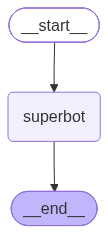

In [19]:
from langgraph.graph import StateGraph, START, END
graph = StateGraph(State)

## Node
graph.add_node("superbot", superbot)
## Edges
graph.add_edge(START, "superbot")
graph.add_edge("superbot", END) 

Graph_builder = graph.compile()

## Display

from IPython.display import Image, display
display(Image(Graph_builder.get_graph().draw_mermaid_png()))    

## Invocation

In [20]:
Graph_builder.invoke({'messages' : "Hi, My name is NAvdeep and i like cricket"})

{'messages': [HumanMessage(content='Hi, My name is NAvdeep and i like cricket', additional_kwargs={}, response_metadata={}, id='a782dd2d-320a-43a6-be4b-dc34c43f2881'),
  AIMessage(content="Hi Navdeep! It's nice to hear from a cricket enthusiast! Who are your favorite teams and players?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 19, 'total_tokens': 41, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4-0613', 'system_fingerprint': None, 'id': 'chatcmpl-EYksq78abYZuzygEdVDOiQXOrGzWe', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a138aa-c29a-7e80-ab5e-f6fe37687870-0', tool_calls=[], inva

### Streaming the Responses

## Streammode = values

In [23]:
for event in Graph_builder.stream({'messages' : "Hi, My name is Navdeep and i like cricket"}, stream_mode="values"):
    print(event)

{'messages': [HumanMessage(content='Hi, My name is Navdeep and i like cricket', additional_kwargs={}, response_metadata={}, id='f6ae4d53-3534-4778-817e-44332fe957c2')]}
{'messages': [HumanMessage(content='Hi, My name is Navdeep and i like cricket', additional_kwargs={}, response_metadata={}, id='f6ae4d53-3534-4778-817e-44332fe957c2'), AIMessage(content="That's fantastic, Navdeep. Cricket is a very popular and exciting game. Do you like to play cricket or are you more of a spectator? Who is your favourite player?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 36, 'prompt_tokens': 18, 'total_tokens': 54, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'g

## Streammode = Updates

In [24]:
for event in Graph_builder.stream({'messages' : "Hi, My name is Navdeep and i like cricket"}, stream_mode="updates"):
    print(event)

{'superbot': {'messages': [AIMessage(content="Hello Navdeep! It's great to meet a fellow cricket enthusiast. Who is your favorite player?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 18, 'total_tokens': 38, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4-0613', 'system_fingerprint': None, 'id': 'chatcmpl-EYl0iyVlHBUUvFA673DjuLqvj0fB7', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a138b2-4087-72e2-86aa-dc7e9760fa41-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 20, 'total_tokens': 38, 'input_token_details': {'audio': 0, 'cache_read': 0},